In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q open_clip_torch gradio scipy opencv-python-headless gdown tqdm pandas
!wget -q -nc https://raw.githubusercontent.com/KaiyangZhou/deep-person-reid/master/torchreid/models/osnet.py -O /content/osnet.py
!ls -la /content/osnet.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.5 MB/s eta 0:00:00
-rw-r--r-- 1 root root 17037 Oct 12 14:34 /content/osnet.py


In [3]:
import os, re, glob, random, math, json, time, zipfile, itertools, sys
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageFilter
from collections import defaultdict
from tqdm.auto import tqdm
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader, Sampler
import matplotlib.pyplot as plt
sys.path.insert(0, '/content')

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '(GPU on karo!)')

WORK = '/content/drive/MyDrive/reid_fyp'
os.makedirs(f'{WORK}/feats', exist_ok=True); os.makedirs(f'{WORK}/ckpt', exist_ok=True)
MARKET_ZIP = f'{WORK}/Market-1501-v15.09.15.zip'
RESULTS = []

Device: cuda Tesla T4


In [5]:
from google.colab import files
files.upload()   # yahan kaggle.json select karo (Kaggle > Settings > API > Create New Token)
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

# Pehle slug check karo (naam yahan se uthao agar neeche wala fail ho)
!kaggle datasets list -s market-1501

# Download (slug mujhe yaad hai, verify nahi kar sakta)
!kaggle datasets download -d pengcw1/market-1501 -p /content/dl

import glob, shutil
z = glob.glob('/content/dl/*.zip')[0]
os.makedirs(WORK, exist_ok=True)
shutil.copy(z, MARKET_ZIP)          # Drive mein reid_fyp/Market-1501-v15.09.15.zip ban gayi
print('Saved:', MARKET_ZIP, round(os.path.getsize(MARKET_ZIP) / 1e6), 'MB')

cp: cannot stat 'kaggle.json': No such file or directory
You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication
Dataset URL: https://www.kaggle.com/datasets/pengcw1/market-1501
License(s): unknown
100% 146M/146M [00:01<00:00, 114MB/s]

Saved: /content/drive/MyDrive/reid_fyp/Market-1501-v15.09.15.zip 153 MB


In [6]:
if not os.path.exists('/content/market'):
    assert os.path.exists(MARKET_ZIP), f'Zip nahi mili: {MARKET_ZIP}'
    with zipfile.ZipFile(MARKET_ZIP) as z: z.extractall('/content/market')
ROOT = os.path.dirname(glob.glob('/content/market/**/bounding_box_train', recursive=True)[0])
print('Market root:', ROOT, os.listdir(ROOT))

pat = re.compile(r'(-?\d+)_c(\d)s(\d)_(\d+)')
def read_dir(d):
    paths, pid, cam, seq, fr = [], [], [], [], []
    for p in sorted(glob.glob(os.path.join(d, '*.jpg'))):
        m = pat.search(os.path.basename(p))
        a, b, c, e = map(int, m.groups())
        paths.append(p); pid.append(a); cam.append(b); seq.append(c); fr.append(e)
    return dict(paths=paths, pid=np.array(pid), cam=np.array(cam), seq=np.array(seq), frame=np.array(fr))

TR = read_dir(f'{ROOT}/bounding_box_train')
Q  = read_dir(f'{ROOT}/query')
G  = read_dir(f'{ROOT}/bounding_box_test')
train_ids = sorted(set(TR['pid'])); id2label = {p: i for i, p in enumerate(train_ids)}
TR['label'] = np.array([id2label[p] for p in TR['pid']])
print(f'Train: {len(TR["paths"])} imgs / {len(train_ids)} ids   Query: {len(Q["paths"])}   Gallery: {len(G["paths"])}')

Market root: /content/market/Market-1501-v15.09.15 ['bounding_box_train', 'query', 'bounding_box_test', 'readme.txt', 'gt_query', 'gt_bbox']
Train: 12936 imgs / 751 ids   Query: 3368   Gallery: 19732


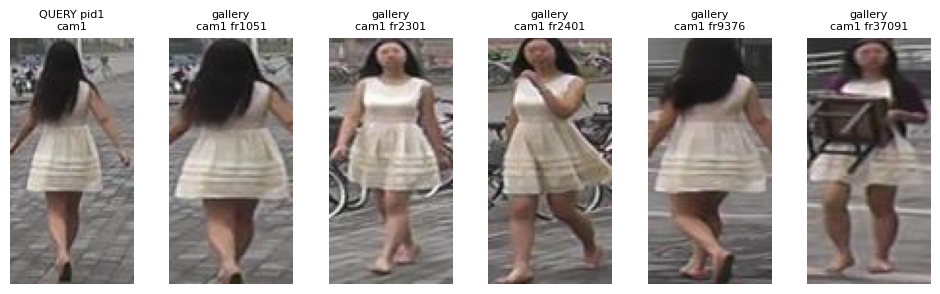

In [7]:
qi = 0; pid = Q['pid'][qi]
pos = [j for j in range(len(G['paths'])) if G['pid'][j] == pid][:5]
fig, ax = plt.subplots(1, 1 + len(pos), figsize=(2 * (1 + len(pos)), 3.2))
ax[0].imshow(Image.open(Q['paths'][qi])); ax[0].set_title(f'QUERY pid{pid}\ncam{Q["cam"][qi]}', fontsize=8)
for a, j in zip(ax[1:], pos):
    a.imshow(Image.open(G['paths'][j])); a.set_title(f'gallery\ncam{G["cam"][j]} fr{G["frame"][j]}', fontsize=8)
for a in ax: a.axis('off')
plt.show()

In [8]:
def evaluate(sim, q_pid, g_pid, q_cam, g_cam, exclude_same_cam=True, ranks=(1, 5, 10)):
    cmcs, aps = [], []
    for i in range(sim.shape[0]):
        order = np.argsort(-sim[i])
        gp, gc = g_pid[order], g_cam[order]
        remove = (gp == -1)
        if exclude_same_cam: remove = remove | ((gp == q_pid[i]) & (gc == q_cam[i]))
        matches = (gp[~remove] == q_pid[i]).astype(np.int32)
        if matches.sum() == 0: continue
        cum = matches.cumsum()
        cmc = (cum > 0).astype(np.float32); cmcs.append(cmc[:max(ranks)])
        aps.append(((cum / (np.arange(len(matches)) + 1.0)) * matches).sum() / matches.sum())
    cmc = np.mean(cmcs, 0)
    out = {f'Rank-{r}': round(float(cmc[r - 1]) * 100, 2) for r in ranks}
    out['mAP'] = round(float(np.mean(aps)) * 100, 2)
    return out

def log_result(name, res, **extra):
    row = dict(name=name, **res, **extra); RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(f'{WORK}/results.csv', index=False)
    print(name, '->', res)

In [9]:
IMN_MEAN, IMN_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)

def tf_test(size, mean, std):
    return T.Compose([T.Resize(size, interpolation=T.InterpolationMode.BICUBIC), T.ToTensor(), T.Normalize(mean, std)])
def tf_train(size, mean, std):
    return T.Compose([T.Resize(size, interpolation=T.InterpolationMode.BICUBIC), T.RandomHorizontalFlip(),
                      T.Pad(10), T.RandomCrop(size), T.ToTensor(), T.Normalize(mean, std),
                      T.RandomErasing(p=0.5, value=0)])

class ImgDS(Dataset):
    def __init__(self, paths, tf, labels=None, degrade=None):
        self.paths, self.tf, self.labels, self.degrade = paths, tf, labels, degrade
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        if self.degrade is not None: img = self.degrade(img, i)
        x = self.tf(img)
        return x if self.labels is None else (x, int(self.labels[i]))

@torch.no_grad()
def extract(encode_fn, paths, tf, degrade=None, bs=128):
    dl = DataLoader(ImgDS(paths, tf, degrade=degrade), batch_size=bs, shuffle=False, num_workers=2)
    out = []
    for x in tqdm(dl, leave=False):
        with torch.autocast('cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
            f = encode_fn(x.to(DEVICE))
        out.append(F.normalize(f.float(), dim=1).cpu())
    return torch.cat(out).numpy()

def cached(name, fn):
    p = f'{WORK}/feats/{name}.npy'
    if os.path.exists(p): return np.load(p)
    a = fn(); np.save(p, a); return a

def make_degrade(kind):
    def f(img, i):
        w, h = img.size
        if kind == 'clean': return img
        if kind == 'blur': return img.filter(ImageFilter.GaussianBlur(radius=2.5))
        if kind == 'lowres':
            return img.resize((max(1, w // 4), max(1, h // 4)), Image.BILINEAR).resize((w, h), Image.BILINEAR)
        if kind == 'occlusion':
            rng = np.random.RandomState(i); ow, oh = int(w * 0.6), int(h * 0.4)
            x0, y0 = rng.randint(0, w - ow + 1), rng.randint(0, h - oh + 1)
            img = img.copy(); img.paste((128, 128, 128), (x0, y0, x0 + ow, y0 + oh)); return img
    return f

def full_eval(qf, gf, name, **extra):
    res = evaluate(qf @ gf.T, Q['pid'], G['pid'], Q['cam'], G['cam'])
    log_result(name, res, **extra); return res

STAGE 1: OSNet baseline without Re-ID training

In [10]:
from osnet import osnet_x1_0

def build_osnet(loss='triplet'):
    try:
        return osnet_x1_0(num_classes=len(train_ids), pretrained=True, loss=loss)
    except Exception as e:
        print('⚠️ ImageNet weights download nahi hue:', e); print('Random init se chal raha hai (accuracy kam hogi)')
        return osnet_x1_0(num_classes=len(train_ids), pretrained=False, loss=loss)

OS_TF = tf_test((256, 128), IMN_MEAN, IMN_STD)
osn = build_osnet().to(DEVICE).eval()
enc = lambda x: osn(x)
qf = cached('osnet_base_q', lambda: extract(enc, Q['paths'], OS_TF))
gf = cached('osnet_base_g', lambda: extract(enc, G['paths'], OS_TF))
full_eval(qf, gf, 'OSNet baseline (ImageNet, no Re-ID training)')
del osn; torch.cuda.empty_cache()

Downloading...
From: https://drive.google.com/uc?id=1LaG1EJpHrxdAxKnSCJ_i0u-nbxSAeiFY
To: /root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth
100%|██████████| 10.9M/10.9M [00:00<00:00, 51.4MB/s]


Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']


  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/155 [00:00<?, ?it/s]

OSNet baseline (ImageNet, no Re-ID training) -> {'Rank-1': 14.52, 'Rank-5': 26.99, 'Rank-10': 34.09, 'mAP': 4.35}


In [11]:
class PKSampler(Sampler):
    def __init__(self, labels, P=16, K=4):
        self.P, self.K = P, K
        self.index = defaultdict(list)
        for i, l in enumerate(labels): self.index[int(l)].append(i)
        self.pids = list(self.index.keys()); self.length = len(labels) // (P * K) * (P * K)
    def __iter__(self):
        pids = self.pids.copy(); random.shuffle(pids); ptr = 0; out = []
        for _ in range(self.length // (self.P * self.K)):
            if ptr + self.P > len(pids): random.shuffle(pids); ptr = 0
            for p in pids[ptr:ptr + self.P]:
                idxs = self.index[p]
                out += random.sample(idxs, self.K) if len(idxs) >= self.K else random.choices(idxs, k=self.K)
            ptr += self.P
        return iter(out)
    def __len__(self): return self.length

def triplet_loss(feats, labels, margin=0.3):
    d = torch.cdist(feats, feats)
    same = labels[:, None] == labels[None, :]
    hardest_pos = (d * same.float()).max(1)[0]
    hardest_neg = (d + 1e5 * same.float()).min(1)[0]
    return F.relu(hardest_pos - hardest_neg + margin).mean()

def fit(model, loader, opt, epochs, ckpt, warmup=3):
    lam = lambda ep: (ep + 1) / warmup if ep < warmup else 0.5 * (1 + math.cos(math.pi * (ep - warmup) / max(1, epochs - warmup)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    scaler = torch.amp.GradScaler('cuda'); ce = nn.CrossEntropyLoss(label_smoothing=0.1)
    start = 0
    if os.path.exists(ckpt + '.state'):
        st = torch.load(ckpt + '.state', map_location=DEVICE, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched']); start = st['epoch'] + 1
        print('Resumed from epoch', start)
    for ep in range(start, epochs):
        model.train(); tot = n = acc = 0; t0 = time.time()
        for x, y in tqdm(loader, leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16):
                logits, feat = model(x)
            loss = ce(logits.float(), y) + triplet_loss(F.normalize(feat.float(), dim=1), y)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * len(y); n += len(y); acc += (logits.argmax(1) == y).sum().item()
        sched.step()
        print(f'epoch {ep+1}/{epochs}  loss {tot/n:.3f}  train-acc {acc/n*100:.1f}%  ({time.time()-t0:.0f}s)')
        torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), epoch=ep), ckpt + '.state')
    torch.save(model.state_dict(), ckpt)

In [12]:
OS_EPOCHS = 25
OS_CKPT = f'{WORK}/ckpt/osnet_ft.pt'
osn = build_osnet('triplet').to(DEVICE)
if not os.path.exists(OS_CKPT):
    ds = ImgDS(TR['paths'], tf_train((256, 128), IMN_MEAN, IMN_STD), TR['label'])
    dl = DataLoader(ds, batch_size=64, sampler=PKSampler(TR['label']), num_workers=2, drop_last=True)
    opt = torch.optim.Adam(osn.parameters(), lr=3.5e-4, weight_decay=5e-4)
    fit(osn, dl, opt, OS_EPOCHS, OS_CKPT)
osn.load_state_dict(torch.load(OS_CKPT, map_location=DEVICE)); osn.eval()
enc = lambda x: osn(x)
qf = cached('osnet_ft_q', lambda: extract(enc, Q['paths'], OS_TF))
gf = cached('osnet_ft_g', lambda: extract(enc, G['paths'], OS_TF))
full_eval(qf, gf, 'OSNet fine-tuned (ID+triplet)')
del osn; torch.cuda.empty_cache()

Successfully loaded imagenet pretrained weights from "/root/.cache/torch/checkpoints/osnet_x1_0_imagenet.pth"
** The following layers are discarded due to unmatched keys or layer size: ['classifier.weight', 'classifier.bias']


  0%|          | 0/202 [00:00<?, ?it/s]

epoch 1/25  loss 6.902  train-acc 2.3%  (54s)


  0%|          | 0/202 [00:00<?, ?it/s]

epoch 2/25  loss 5.851  train-acc 17.3%  (49s)


...

  0%|          | 0/202 [00:00<?, ?it/s]

epoch 25/25  loss 1.152  train-acc 99.6%  (51s)


  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/155 [00:00<?, ?it/s]

OSNet fine-tuned (ID+triplet) -> {'Rank-1': 91.78, 'Rank-5': 96.64, 'Rank-10': 98.16, 'mAP': 80.15}


In [13]:
import open_clip

class CLIPReID(nn.Module):
    def __init__(self, n_ids, n_train_blocks=4):
        super().__init__()
        clip, _, _ = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
        self.visual = clip.visual.float()
        for p in self.visual.parameters(): p.requires_grad = False
        v = self.visual
        for m in list(v.transformer.resblocks)[-n_train_blocks:] + [v.ln_post]:
            for p in m.parameters(): p.requires_grad = True
        v.proj.requires_grad = True
        self.bn = nn.BatchNorm1d(512); self.bn.bias.requires_grad_(False)
        self.cls = nn.Linear(512, n_ids, bias=False); nn.init.normal_(self.cls.weight, std=0.001)
    def backbone_params(self): return [p for p in self.visual.parameters() if p.requires_grad]
    def forward(self, x):
        f = self.visual(x); fb = self.bn(f)
        return (self.cls(fb), f) if self.training else fb

CLIP_EPOCHS = 15
CLIP_CKPT = f'{WORK}/ckpt/clip_ft.pt'
CLIP_TF = tf_test((224, 224), CLIP_MEAN, CLIP_STD)
clip_ft = CLIPReID(len(train_ids)).to(DEVICE)
print('Trainable params:', sum(p.numel() for p in clip_ft.parameters() if p.requires_grad) / 1e6, 'M')
if not os.path.exists(CLIP_CKPT):
    ds = ImgDS(TR['paths'], tf_train((224, 224), CLIP_MEAN, CLIP_STD), TR['label'])
    dl = DataLoader(ds, batch_size=64, sampler=PKSampler(TR['label']), num_workers=2, drop_last=True)
    opt = torch.optim.AdamW([dict(params=clip_ft.backbone_params(), lr=2e-5),
                             dict(params=list(clip_ft.bn.parameters()) + list(clip_ft.cls.parameters()), lr=1e-3)],
                            weight_decay=1e-4)
    fit(clip_ft, dl, opt, CLIP_EPOCHS, CLIP_CKPT)
clip_ft.load_state_dict(torch.load(CLIP_CKPT, map_location=DEVICE)); clip_ft.eval()
enc = lambda x: clip_ft(x)
qf = cached('clipft_q', lambda: extract(enc, Q['paths'], CLIP_TF))
gf = cached('clipft_g', lambda: extract(enc, G['paths'], CLIP_TF))
full_eval(qf, gf, 'CLIP ViT-B/32 fine-tuned (last 4 blocks)')

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Trainable params: 29.131264 M


  0%|          | 0/202 [00:00<?, ?it/s]

...

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/155 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ccbdfde6ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ccbdfde6ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

CLIP ViT-B/32 fine-tuned (last 4 blocks) -> {'Rank-1': 83.58, 'Rank-5': 94.03, 'Rank-10': 96.29, 'mAP': 66.04}


{'Rank-1': 83.58, 'Rank-5': 94.03, 'Rank-10': 96.29, 'mAP': 66.04}

In [14]:
clip_zs, _, _ = open_clip.create_model_and_transforms('ViT-B-32', pretrained='openai')
clip_zs = clip_zs.to(DEVICE).eval()
tok = open_clip.get_tokenizer('ViT-B-32')
enc = lambda x: clip_zs.encode_image(x)
qz = cached('clipzs_q', lambda: extract(enc, Q['paths'], CLIP_TF))
gz = cached('clipzs_g', lambda: extract(enc, G['paths'], CLIP_TF))
full_eval(qz, gz, 'CLIP ViT-B/32 zero-shot (image->image)')
pd.DataFrame(RESULTS)

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/155 [00:00<?, ?it/s]

CLIP ViT-B/32 zero-shot (image->image) -> {'Rank-1': 7.63, 'Rank-5': 15.65, 'Rank-10': 21.53, 'mAP': 1.98}


,name,Rank-1,Rank-5,Rank-10,mAP
0,"OSNet baseline (ImageNet, no Re-ID training)",14.52,26.99,34.09,4.35
1,OSNet fine-tuned (ID+triplet),91.78,96.64,98.16,80.15
2,CLIP ViT-B/32 fine-tuned (last 4 blocks),83.58,94.03,96.29,66.04
3,CLIP ViT-B/32 zero-shot (image->image),7.63,15.65,21.53,1.98


In [15]:
!wget -q -nc https://raw.githubusercontent.com/vana77/Market-1501_Attribute/master/market_attribute.mat -O /content/market_attribute.mat
ATTR_PATH = '/content/market_attribute.mat' if os.path.getsize('/content/market_attribute.mat') > 1000 else f'{WORK}/market_attribute.mat'
print('Using', ATTR_PATH)

import scipy.io as sio
ma = sio.loadmat(ATTR_PATH, struct_as_record=False, squeeze_me=True)['market_attribute']
split = ma.test
fields = [f for f in split._fieldnames if f != 'image_index']
ids = [int(str(x)) for x in split.image_index]
ATTRS = {pid: {f: int(getattr(split, f)[i]) for f in fields} for i, pid in enumerate(ids)}
print(len(ATTRS), 'ids with attributes. Fields:', fields)
print(ids[0], ATTRS[ids[0]])

Using /content/market_attribute.mat
750 ids with attributes. Fields: ['age', 'backpack', 'bag', 'handbag', 'clothes', 'down', 'up', 'hair', 'hat', 'gender', 'upblack', 'upwhite', 'upred', 'uppurple', 'upyellow', 'upgray', 'upblue', 'upgreen', 'downblack', 'downwhite', 'downpink', 'downpurple', 'downyellow', 'downgray', 'downblue', 'downgreen', 'downbrown']
1 {'age': 2, 'backpack': 1, 'bag': 1, 'handbag': 1, 'clothes': 1, 'down': 2, 'up': 2, 'hair': 2, 'hat': 1, 'gender': 2, 'upblack': 1, 'upwhite': 2, 'upred': 1, 'uppurple': 1, 'upyellow': 1, 'upgray': 1, 'upblue': 1, 'upgreen': 1, 'downblack': 1, 'downwhite': 2, 'downpink': 1, 'downpurple': 1, 'downyellow': 1, 'downgray': 1, 'downblue': 1, 'downgreen': 1, 'downbrown': 1}


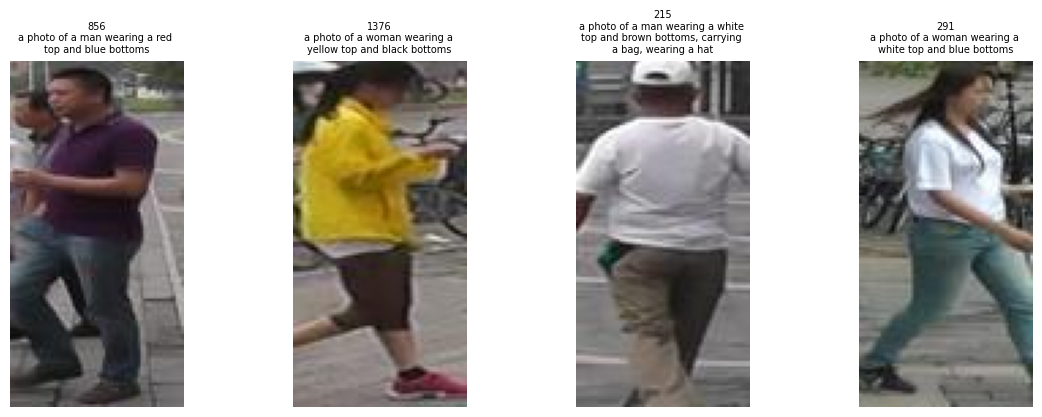

In [17]:
UP   = ['black', 'white', 'red', 'purple', 'yellow', 'gray', 'blue', 'green']
DOWN = ['black', 'white', 'pink', 'purple', 'yellow', 'gray', 'blue', 'green', 'brown']

def attrs_to_sentence(a):
    s = 'a photo of a ' + ('man' if a['gender'] == 1 else 'woman')
    up = [c for c in UP if a['up' + c] == 2]; dn = [c for c in DOWN if a['down' + c] == 2]
    if up: s += ' wearing a ' + ' and '.join(up) + ' top'
    if dn: s += (' and ' if up else ' wearing ') + ' and '.join(dn) + ' bottoms'
    carry = [n for k, n in [('backpack', 'a backpack'), ('bag', 'a bag'), ('handbag', 'a handbag')] if a[k] == 2]
    if carry: s += ', carrying ' + ' and '.join(carry)
    if a['hat'] == 2: s += ', wearing a hat'
    return s

SENT = {pid: attrs_to_sentence(a) for pid, a in ATTRS.items()}
chk = random.sample(list(SENT), 4)
fig, ax = plt.subplots(1, 4, figsize=(14, 4.5))
for a, pid in zip(ax, chk):
    j = next(k for k in range(len(G['paths'])) if G['pid'][k] == pid)
    a.imshow(Image.open(G['paths'][j])); a.axis('off')
    a.set_title(f'{pid}\n' + '\n'.join(re.findall('.{1,32}(?:\\s|$)', SENT[pid])), fontsize=7)
plt.show()

In [18]:
@torch.no_grad()
def encode_text(sentences):
    out = []
    for i in range(0, len(sentences), 128):
        t = tok(sentences[i:i + 128]).to(DEVICE)
        out.append(F.normalize(clip_zs.encode_text(t).float(), dim=1).cpu())
    return torch.cat(out).numpy()

pid_list = sorted(SENT); TXT = dict(zip(pid_list, encode_text([SENT[p] for p in pid_list])))
TQ = np.stack([TXT[p] for p in Q['pid']])
S_txt = TQ @ gz.T
res = evaluate(S_txt, Q['pid'], G['pid'], Q['cam'], G['cam'])
log_result('Text-only (zero-shot CLIP, attribute sentence)', res)

Text-only (zero-shot CLIP, attribute sentence) -> {'Rank-1': 1.69, 'Rank-5': 6.62, 'Rank-10': 10.9, 'mAP': 1.27}


In [19]:
BEST_IMG = 'clipft'     # 'clipft' ya 'osnet': jo Table 1 mein behtar tha wo likho

if BEST_IMG == 'clipft':
    img_enc = lambda x: clip_ft(x); IMG_TF = CLIP_TF; G_IMG = np.load(f'{WORK}/feats/clipft_g.npy')
else:
    osn = build_osnet('triplet').to(DEVICE); osn.load_state_dict(torch.load(OS_CKPT, map_location=DEVICE)); osn.eval()
    img_enc = lambda x: osn(x); IMG_TF = OS_TF; G_IMG = np.load(f'{WORK}/feats/osnet_ft_g.npy')

DEG = ['clean', 'blur', 'lowres', 'occlusion']
QF = {k: cached(f'{BEST_IMG}_q_{k}', lambda k=k: extract(img_enc, Q['paths'], IMG_TF, degrade=make_degrade(k))) for k in DEG}

import cv2
def sharpness(img):
    g = np.array(img.convert('L').resize((64, 128))); return cv2.Laplacian(g, cv2.CV_64F).var()
SHARP = {}
for k in DEG:
    d = make_degrade(k)
    SHARP[k] = np.array([sharpness(d(Image.open(p).convert('RGB'), i)) for i, p in enumerate(Q['paths'])])
    print(k, 'median sharpness:', np.median(SHARP[k]).round(1))

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

clean median sharpness: 976.0
blur median sharpness: 8.2
lowres median sharpness: 14.4
occlusion median sharpness: 928.3


In [20]:
def zs(S): return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-8)
S_TXT_Z = zs(S_txt)

_s = np.log1p(SHARP['clean']); LO, HI = np.percentile(_s, [10, 90])
def adaptive_w(sharp, wmin=0.2, wmax=0.9):
    a = np.clip((np.log1p(sharp) - LO) / (HI - LO), 0, 1); return (wmin + (wmax - wmin) * a)[:, None]

rows = []
for k in DEG:
    S_img = zs(QF[k] @ G_IMG.T)
    variants = {'image-only': S_img, 'text-only': S_TXT_Z}
    for w in [0.3, 0.5, 0.7]: variants[f'fixed w={w}'] = w * S_img + (1 - w) * S_TXT_Z
    wa = adaptive_w(SHARP[k]); variants['adaptive'] = wa * S_img + (1 - wa) * S_TXT_Z
    for name, S in variants.items():
        r = evaluate(S, Q['pid'], G['pid'], Q['cam'], G['cam']); rows.append(dict(query=k, method=name, **r))
        print(f'{k:10s} {name:12s}', r)
    print('   mean adaptive w on', k, '=', wa.mean().round(3))
FUSION = pd.DataFrame(rows); FUSION.to_csv(f'{WORK}/fusion_table.csv', index=False)
FUSION.pivot(index='method', columns='query', values='mAP')

clean      image-only   {'Rank-1': 83.58, 'Rank-5': 94.03, 'Rank-10': 96.29, 'mAP': 66.04}
clean      text-only    {'Rank-1': 1.69, 'Rank-5': 6.62, 'Rank-10': 10.9, 'mAP': 1.27}
clean      fixed w=0.3  {'Rank-1': 53.38, 'Rank-5': 77.94, 'Rank-10': 84.95, 'mAP': 27.91}
clean      fixed w=0.5  {'Rank-1': 77.17, 'Rank-5': 91.42, 'Rank-10': 95.1, 'mAP': 54.01}
clean      fixed w=0.7  {'Rank-1': 83.43, 'Rank-5': 93.91, 'Rank-10': 96.56, 'mAP': 64.01}
clean      adaptive     {'Rank-1': 73.43, 'Rank-5': 86.49, 'Rank-10': 90.56, 'mAP': 53.71}
   mean adaptive w on clean = 0.594
blur       image-only   {'Rank-1': 37.86, 'Rank-5': 59.38, 'Rank-10': 67.52, 'mAP': 28.01}
blur       text-only    {'Rank-1': 1.69, 'Rank-5': 6.62, 'Rank-10': 10.9, 'mAP': 1.27}
blur       fixed w=0.3  {'Rank-1': 23.63, 'Rank-5': 44.03, 'Rank-10': 53.83, 'mAP': 11.87}
blur       fixed w=0.5  {'Rank-1': 35.93, 'Rank-5': 59.26, 'Rank-10': 68.97, 'mAP': 23.65}
blur       fixed w=0.7  {'Rank-1': 40.94, 'Rank-5': 62.35, 'Ran

query,blur,clean,lowres,occlusion
method,,,,
adaptive,6.21,53.71,6.93,40.53
fixed w=0.3,11.87,27.91,13.63,19.44
fixed w=0.5,23.65,54.01,27.72,38.61
fixed w=0.7,29.02,64.01,34.32,46.32
image-only,28.01,66.04,34.22,46.99
text-only,1.27,1.27,1.27,1.27


In [21]:
FPS = 25
def estimate_topology(tr, pct_lo=1, pct_hi=99, min_pairs=20):
    groups = defaultdict(list)
    for pid, cam, seq, fr in zip(tr['pid'], tr['cam'], tr['seq'], tr['frame']): groups[(pid, seq)].append((cam, fr))
    dts = defaultdict(list)
    for lst in groups.values():
        if len(lst) > 60: lst = random.sample(lst, 60)
        for (c1, f1), (c2, f2) in itertools.combinations(lst, 2):
            if c1 != c2: dts[(c1, c2)].append(abs(f1 - f2) / FPS); dts[(c2, c1)].append(abs(f1 - f2) / FPS)
    MIN, MAX = np.zeros((6, 6)), np.full((6, 6), np.inf)
    for (a, b), v in dts.items():
        if len(v) >= min_pairs: MIN[a - 1, b - 1] = np.percentile(v, pct_lo); MAX[a - 1, b - 1] = np.percentile(v, pct_hi)
    return MIN, MAX, dts

def apply_filter(S, q, g, MIN=None, MAX=None, bad_val=-1e9):
    same_seq = q['seq'][:, None] == g['seq'][None, :]
    diff_cam = q['cam'][:, None] != g['cam'][None, :]
    dt = np.abs(q['frame'][:, None].astype(np.float32) - g['frame'][None, :].astype(np.float32)) / FPS
    qi, gi = (q['cam'][:, None] - 1), (g['cam'][None, :] - 1)
    bad = np.zeros_like(same_seq)
    if MIN is not None: bad |= dt < MIN[qi, gi]
    if MAX is not None: bad |= dt > MAX[qi, gi]
    bad &= same_seq & diff_cam
    same_id = (q['pid'][:, None] == g['pid'][None, :]); valid_g = (g['pid'][None, :] != -1)
    stats = dict(removed_total=int((bad & valid_g).sum()), removed_true_matches=int((bad & same_id & valid_g).sum()),
                 true_matches_total=int((same_id & diff_cam & valid_g).sum()))
    S2 = S.copy(); S2[bad] = bad_val
    return S2, stats

MIN_EST, MAX_EST, DTS = estimate_topology(TR)
print('Camera pair -> (#pairs, min-travel(1%) sec, max-window(99%) sec)')
for a in range(1, 7):
    print(f'cam{a}:', ' '.join(f'{b}:({len(DTS[(a,b)])},{MIN_EST[a-1,b-1]:.1f},{MAX_EST[a-1,b-1]:.0f})' if (a, b) in DTS else f'{b}:-' for b in range(1, 7) if b != a))
seq_per_id = pd.Series(TR['seq']).groupby(TR['pid']).nunique()
print('Average #sequences per person in train:', seq_per_id.mean().round(2))
ASSUMED_MIN = np.full((6, 6), 3.0); np.fill_diagonal(ASSUMED_MIN, 0)

Camera pair -> (#pairs, min-travel(1%) sec, max-window(99%) sec)
cam1: 2:(995,4.0,4904) 3:(1530,3.3,4948) 4:(2386,0.2,1834) 5:(2373,0.0,3885) 6:(2994,1.0,2893)
cam2: 1:(995,4.0,4904) 3:(6275,3.0,3380) 4:(305,1.0,2116) 5:(4901,3.1,3044) 6:(6103,2.2,2861)
cam3: 1:(1530,3.3,4948) 2:(6275,3.0,3380) 4:(469,1.0,4933) 5:(10330,5.3,3010) 6:(13802,12.0,2918)
cam4: 1:(2386,0.2,1834) 2:(305,1.0,2116) 3:(469,1.0,4933) 5:(824,0.0,4842) 6:(746,2.0,4221)
cam5: 1:(2373,0.0,3885) 2:(4901,3.1,3044) 3:(10330,5.3,3010) 4:(824,0.0,4842) 6:(13859,1.0,2987)
cam6: 1:(2994,1.0,2893) 2:(6103,2.2,2861) 3:(13802,12.0,2918) 4:(746,2.0,4221) 5:(13859,1.0,2987)
Average #sequences per person in train: 2.03


In [22]:
KIND = 'blur'
S_img = zs(QF[KIND] @ G_IMG.T); wa = adaptive_w(SHARP[KIND]); S_FUSED = wa * S_img + (1 - wa) * S_TXT_Z

rows = []
for name, mn, mx in [('no filter', None, None), ('assumed min=3s', ASSUMED_MIN, None),
                     ('estimated min only', MIN_EST, None), ('estimated min + max window', MIN_EST, MAX_EST)]:
    if mn is None and mx is None: S2, st = S_FUSED, dict(removed_total=0, removed_true_matches=0, true_matches_total=0)
    else: S2, st = apply_filter(S_FUSED, Q, G, mn, mx)
    r = evaluate(S2, Q['pid'], G['pid'], Q['cam'], G['cam'])
    rows.append(dict(filter=name, **r, **st)); print(name, r, st)
TEMPORAL = pd.DataFrame(rows); TEMPORAL.to_csv(f'{WORK}/temporal_table.csv', index=False); TEMPORAL

no filter {'Rank-1': 13.63, 'Rank-5': 30.02, 'Rank-10': 38.87, 'mAP': 6.21} {'removed_total': 0, 'removed_true_matches': 0, 'true_matches_total': 0}
assumed min=3s {'Rank-1': 13.54, 'Rank-5': 29.87, 'Rank-10': 38.75, 'mAP': 6.15} {'removed_total': 12705, 'removed_true_matches': 671, 'true_matches_total': 49649}
estimated min only {'Rank-1': 13.57, 'Rank-5': 29.96, 'Rank-10': 38.81, 'mAP': 6.17} {'removed_total': 15094, 'removed_true_matches': 281, 'true_matches_total': 49649}
estimated min + max window {'Rank-1': 13.84, 'Rank-5': 30.43, 'Rank-10': 39.28, 'mAP': 6.31} {'removed_total': 1655076, 'removed_true_matches': 440, 'true_matches_total': 49649}


,filter,Rank-1,Rank-5,Rank-10,mAP,removed_total,removed_true_matches,true_matches_total
0,no filter,13.63,30.02,38.87,6.21,0,0,0
1,assumed min=3s,13.54,29.87,38.75,6.15,12705,671,49649
2,estimated min only,13.57,29.96,38.81,6.17,15094,281,49649
3,estimated min + max window,13.84,30.43,39.28,6.31,1655076,440,49649


In [23]:
S_ROUTE, _ = apply_filter(S_FUSED, Q, G, MIN_EST, MAX_EST)

def build_route(scores_row, k=10):
    order = [j for j in np.argsort(-scores_row)[:60] if G['pid'][j] != -1][:k]
    best = {}
    for j in order: best.setdefault(G['cam'][j], j)
    steps = sorted(best.values(), key=lambda j: (G['seq'][j], G['frame'][j]))
    return order, steps

def route_str(steps, true_pid=None):
    s = []
    for j in steps:
        ok = '' if true_pid is None else (' ✓' if G['pid'][j] == true_pid else ' ✗')
        s.append(f'cam{G["cam"][j]} (seq{G["seq"][j]}, t={G["frame"][j]/FPS:.0f}s){ok}')
    return '  →  '.join(s)

for qi in random.sample(range(len(Q['paths'])), 4):
    order, steps = build_route(S_ROUTE[qi])
    print(f'Query {qi} (pid {Q["pid"][qi]}, cam{Q["cam"][qi]}):  ', route_str(steps, Q['pid'][qi]))

Query 704 (pid 304, cam6):   cam5 (seq1, t=2743s) ✓  →  cam6 (seq2, t=4205s) ✗  →  cam2 (seq3, t=2657s) ✗
Query 1524 (pid 723, cam5):   cam6 (seq2, t=2226s) ✗  →  cam2 (seq2, t=2406s) ✗  →  cam3 (seq2, t=4139s) ✗  →  cam1 (seq4, t=1371s) ✗
Query 791 (pid 346, cam3):   cam1 (seq2, t=17s) ✗  →  cam2 (seq2, t=5500s) ✗  →  cam3 (seq3, t=2676s) ✗  →  cam4 (seq6, t=733s) ✗
Query 3026 (pid 1357, cam5):   cam6 (seq1, t=2255s) ✗  →  cam4 (seq2, t=1226s) ✗  →  cam3 (seq2, t=4600s) ✗  →  cam2 (seq3, t=2201s) ✗  →  cam1 (seq4, t=2717s) ✗


In [24]:
from transformers import AutoProcessor
try: from transformers import AutoModelForImageTextToText as AutoVLM
except ImportError: from transformers import AutoModelForVision2Seq as AutoVLM
try: del clip_ft
except NameError: pass
torch.cuda.empty_cache()

VLM_NAME = 'HuggingFaceTB/SmolVLM-Instruct'     # tez chahiye to 'HuggingFaceTB/SmolVLM-500M-Instruct'
processor = AutoProcessor.from_pretrained(VLM_NAME, do_image_splitting=False)
vlm = AutoVLM.from_pretrained(VLM_NAME, torch_dtype=torch.float16).to(DEVICE).eval()

def up(img): return img.convert('RGB').resize((192, 384), Image.BICUBIC)
@torch.no_grad()
def vlm_ask(images, question, max_new_tokens=150):
    content = [{'type': 'image'} for _ in images] + [{'type': 'text', 'text': question}]
    prompt = processor.apply_chat_template([{'role': 'user', 'content': content}], add_generation_prompt=True)
    inputs = processor(text=prompt, images=[up(i) for i in images], return_tensors='pt')
    inputs = {k: (v.to(DEVICE, torch.float16) if v.dtype.is_floating_point else v.to(DEVICE)) for k, v in inputs.items()}
    out = vlm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return processor.batch_decode(out, skip_special_tokens=True)[0].split('Assistant:')[-1].strip()

PAIR_Q = ('Image 1 and Image 2 are CCTV crops of two people. Decide whether they are the SAME person or DIFFERENT people. '
          'Start your answer with exactly one word: SAME or DIFFERENT. Then describe the clothing of each person '
          '(top colour, bottom colour, bag) and say which details match and which do not.')
def parse_verdict(t):
    m = re.search(r'\b(SAME|DIFFERENT)\b', t.upper()[:40]); return m.group(1) if m else 'UNKNOWN'

qi = 0; pid = Q['pid'][qi]; j = next(k for k in range(len(G['paths'])) if G['pid'][k] == pid and G['cam'][k] != Q['cam'][qi])
ans = vlm_ask([Image.open(Q['paths'][qi]), Image.open(G['paths'][j])], PAIR_Q); print(parse_verdict(ans), '\n', ans)

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/7.45k [00:00<?, ?B/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


...

model.safetensors: reconstructing file:   0%|          |  0.00B / 4.49GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

DIFFERENT 
 DIFFERENT.


In [25]:
N_PAIRS = 50
KEYS = ['gender', 'backpack', 'bag', 'handbag', 'hat'] + ['up' + c for c in UP] + ['down' + c for c in DOWN]
VEC = {p: np.array([ATTRS[p][k] for k in KEYS]) for p in ATTRS}
g_by_pid = defaultdict(list)
for j, p in enumerate(G['pid']): g_by_pid[p].append(j)

def hardest_other(p):
    d = {o: int((VEC[o] != VEC[p]).sum()) for o in VEC if o != p and o in g_by_pid}
    m = min(d.values()); return random.choice([o for o, v in d.items() if v == m]), m

rng = random.Random(1); pairs = []
cand = [i for i in range(len(Q['paths'])) if Q['pid'][i] in ATTRS]
for qi in rng.sample(cand, N_PAIRS):
    p, cq = Q['pid'][qi], Q['cam'][qi]
    pos = [j for j in g_by_pid[p] if G['cam'][j] != cq]
    if not pos: continue
    hp, dist = hardest_other(p); rp = rng.choice([o for o in VEC if o != p and o in g_by_pid])
    pairs += [('positive', qi, rng.choice(pos), p, p), ('hard_negative', qi, rng.choice(g_by_pid[hp]), p, hp),
              ('random_negative', qi, rng.choice(g_by_pid[rp]), p, rp)]
print(len(pairs), 'pairs ready')
hn = [x for x in pairs if x[0] == 'hard_negative'][0]
print('Query  :', SENT[hn[3]]); print('Partner:', SENT[hn[4]])

150 pairs ready
Query  : a photo of a woman wearing a gray top and blue bottoms, carrying a bag
Partner: a photo of a woman wearing a gray top and blue bottoms, carrying a bag


In [26]:
log = []
for kind, qi, gj, p1, p2 in tqdm(pairs):
    ans = vlm_ask([Image.open(Q['paths'][qi]), Image.open(G['paths'][gj])], PAIR_Q)
    log.append(dict(group=kind, q_idx=qi, g_idx=gj, pid_q=p1, pid_g=p2, verdict=parse_verdict(ans), text=ans))
VLM_LOG = pd.DataFrame(log); VLM_LOG.to_csv(f'{WORK}/vlm_pairs_log.csv', index=False)

tab = VLM_LOG.groupby('group')['verdict'].value_counts().unstack(fill_value=0)
for c in ['SAME', 'DIFFERENT', 'UNKNOWN']:
    if c not in tab: tab[c] = 0
tab['n'] = tab[['SAME', 'DIFFERENT', 'UNKNOWN']].sum(1); tab['%_said_SAME'] = (tab['SAME'] / tab['n'] * 100).round(1)
VLM_TABLE = tab.loc[['positive', 'hard_negative', 'random_negative']]; VLM_TABLE.to_csv(f'{WORK}/vlm_control_table.csv'); VLM_TABLE

  0%|          | 0/150 [00:00<?, ?it/s]

verdict,DIFFERENT,SAME,UNKNOWN,n,%_said_SAME
group,,,,,
positive,50,0,0,50,0.0
hard_negative,49,1,0,50,2.0
random_negative,50,0,0,50,0.0


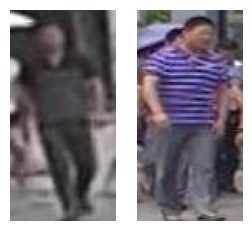

pid 34 vs pid 1221 (DIFFERENT) -> VLM: SAME. Top: purple, bottom: blue, bag: no.



In [27]:
bad = VLM_LOG[(VLM_LOG.group == 'hard_negative') & (VLM_LOG.verdict == 'SAME')].head(4)
for _, r in bad.iterrows():
    fig, ax = plt.subplots(1, 2, figsize=(3, 2.8))
    ax[0].imshow(Image.open(Q['paths'][r.q_idx])); ax[1].imshow(Image.open(G['paths'][r.g_idx]))
    for a in ax: a.axis('off')
    plt.show(); print(f'pid {r.pid_q} vs pid {r.pid_g} (DIFFERENT) -> VLM: {r.text[:300]}\n')

In [28]:
N_DESC = 80
DESC_Q = ('Describe this person: top colour, bottom colour, and whether they carry a backpack. '
          'Answer in one short sentence using simple colour words.')
def has(text, col): t = text.lower().replace('grey', 'gray'); return col in t
rows = []
for j in random.Random(2).sample([j for j in range(len(G['paths'])) if G['pid'][j] in ATTRS], N_DESC):
    a = ATTRS[G['pid'][j]]; txt = vlm_ask([Image.open(G['paths'][j])], DESC_Q, 60)
    gt_up = [c for c in UP if a['up' + c] == 2]; gt_dn = [c for c in DOWN if a['down' + c] == 2]
    rows.append(dict(top_ok=any(has(txt, c) for c in gt_up) if gt_up else np.nan,
                     bottom_ok=any(has(txt, c) for c in gt_dn) if gt_dn else np.nan,
                     backpack_ok=(('backpack' in txt.lower()) == (a['backpack'] == 2)), text=txt))
EXPL = pd.DataFrame(rows); EXPL.to_csv(f'{WORK}/vlm_explanation_check.csv', index=False)
print(f'Top colour mentioned correctly   : {EXPL.top_ok.mean()*100:.1f}%')
print(f'Bottom colour mentioned correctly: {EXPL.bottom_ok.mean()*100:.1f}%')
print(f'Backpack present/absent correct  : {EXPL.backpack_ok.mean()*100:.1f}%')

Top colour mentioned correctly   : 76.7%
Bottom colour mentioned correctly: 64.3%
Backpack present/absent correct  : 83.8%
